# ARIMA_MODEL

### Step 1

In [1]:
# Cell 0 - imports and helper functions
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.max_open_warning": 0})


In [4]:
# Cell 1 - load data and inspect
df = pd.read_csv('Walmart.csv')
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.sort_values(['Store','Date']).reset_index(drop=True)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Unique stores:", df['Store'].nunique())
print("Date range:", df['Date'].min().date(), "to", df['Date'].max().date())

# Show head
display(df.head())


Shape: (6435, 8)
Columns: ['Store', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']
Unique stores: 45
Date range: 2010-02-05 to 2012-10-26


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106


Correlation and pairwise plots between Weekly_Sales and other features


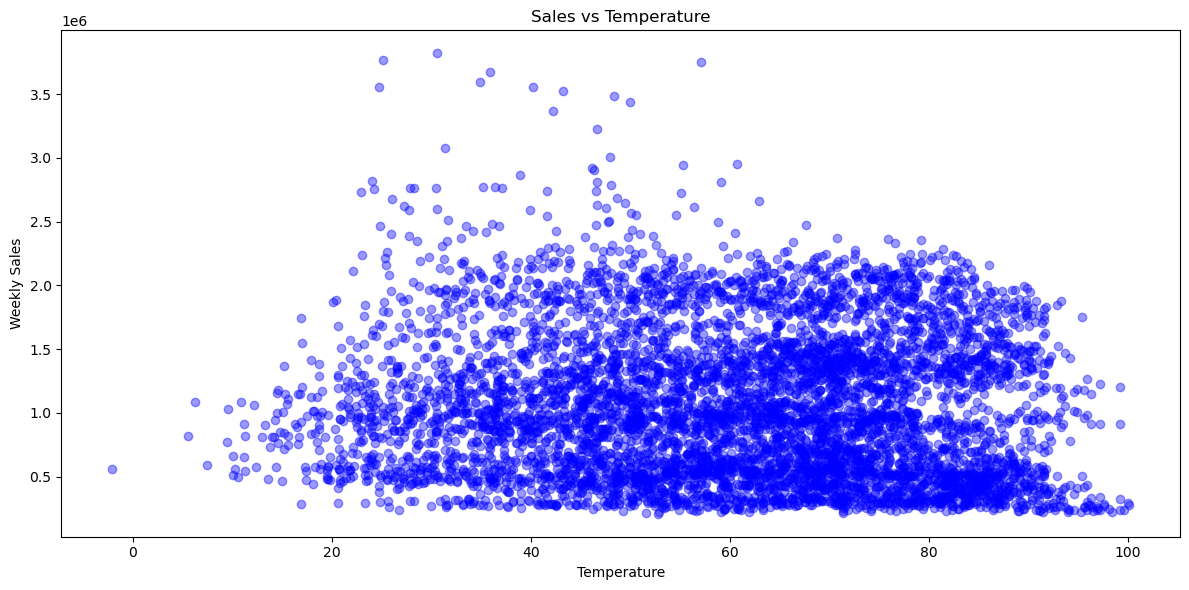

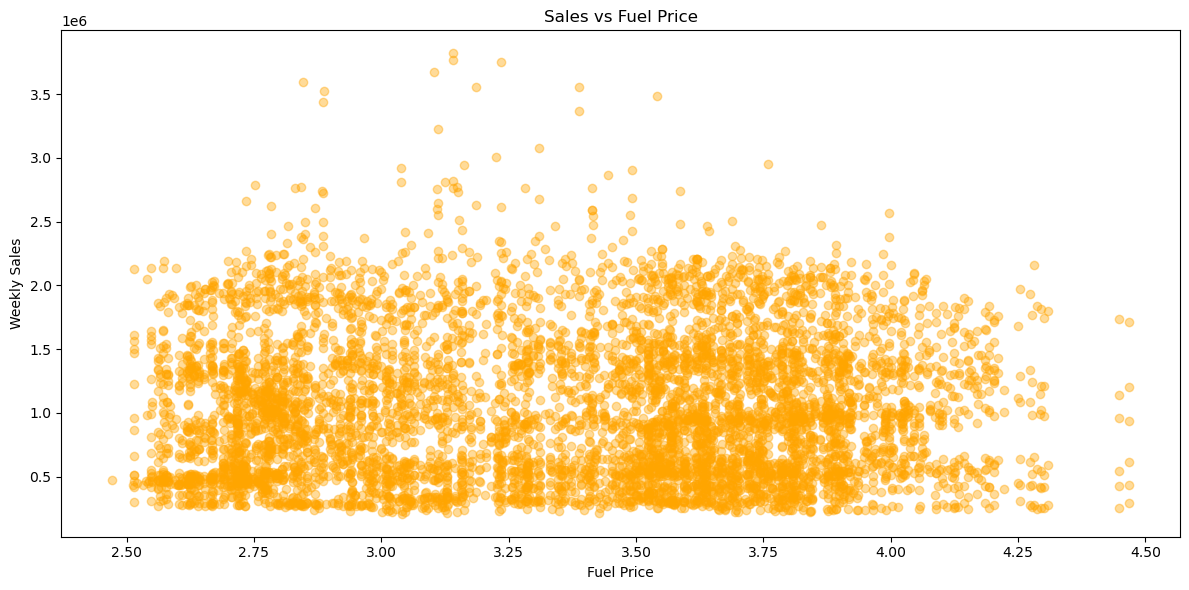

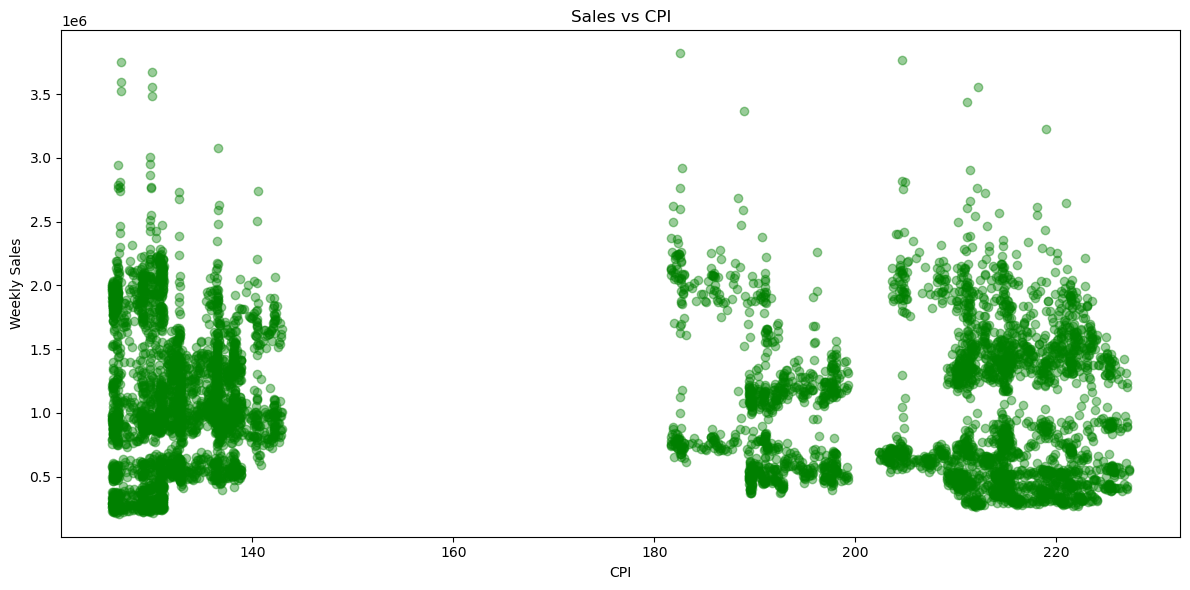

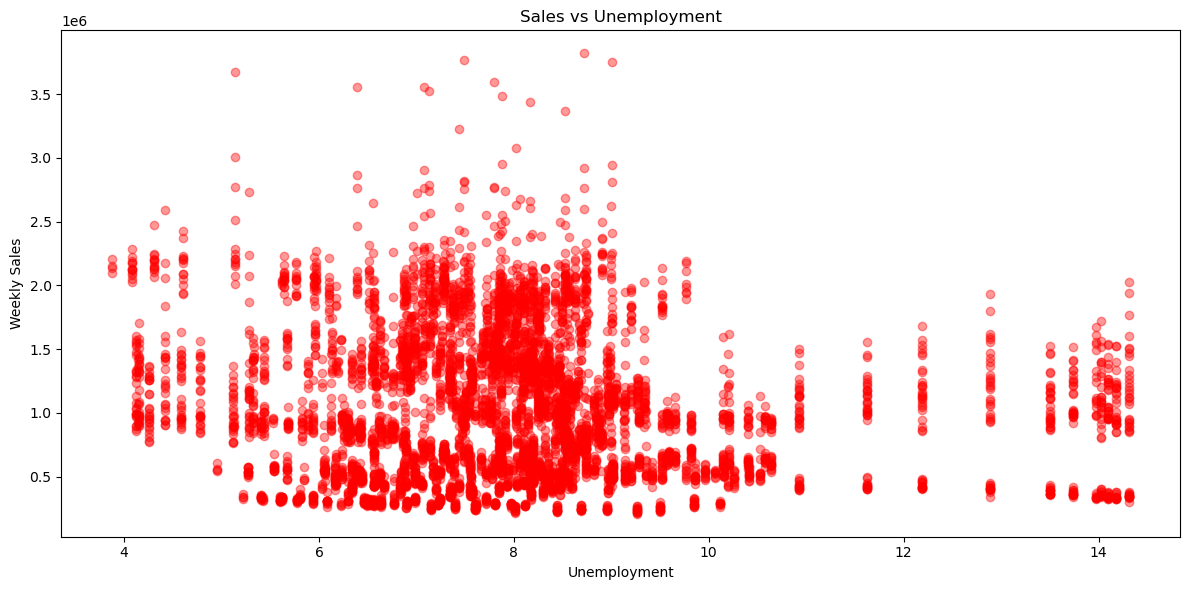

In [34]:
# Cell X - Exploratory analysis: Sales vs other variables

import seaborn as sns
import matplotlib.pyplot as plt

# Compute average weekly sales per store (to smooth a bit)
# or use full data directly depending on what you want
print("Correlation and pairwise plots between Weekly_Sales and other features")

num_cols = ['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']

# 1️⃣ Sales vs. Temperature
plt.figure(figsize=(12,6))
plt.scatter(df['Temperature'], df['Weekly_Sales'], alpha=0.4, color='blue')
plt.title("Sales vs Temperature")
plt.xlabel("Temperature")
plt.ylabel("Weekly Sales")
plt.tight_layout(); plt.show()

# 2️⃣ Sales vs. Fuel Price
plt.figure(figsize=(12,6))
plt.scatter(df['Fuel_Price'], df['Weekly_Sales'], alpha=0.4, color='orange')
plt.title("Sales vs Fuel Price")
plt.xlabel("Fuel Price")
plt.ylabel("Weekly Sales")
plt.tight_layout(); plt.show()

# 3️⃣ Sales vs. CPI
plt.figure(figsize=(12,6))
plt.scatter(df['CPI'], df['Weekly_Sales'], alpha=0.4, color='green')
plt.title("Sales vs CPI")
plt.xlabel("CPI")
plt.ylabel("Weekly Sales")
plt.tight_layout(); plt.show()

# 4️⃣ Sales vs. Unemployment
plt.figure(figsize=(12,6))
plt.scatter(df['Unemployment'], df['Weekly_Sales'], alpha=0.4, color='red')
plt.title("Sales vs Unemployment")
plt.xlabel("Unemployment")
plt.ylabel("Weekly Sales")
plt.tight_layout(); plt.show()


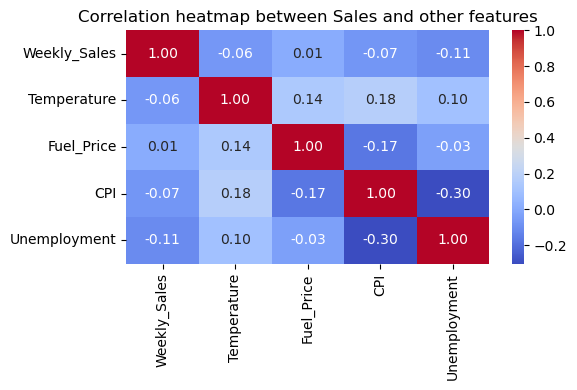

Weekly_Sales    1.000000
Fuel_Price      0.009464
Temperature    -0.063810
CPI            -0.072634
Unemployment   -0.106176
Name: Weekly_Sales, dtype: float64


In [27]:
# Cell Y - Correlation matrix heatmap
corr = df[num_cols].corr()

plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation heatmap between Sales and other features")
plt.tight_layout()
plt.show()

print(corr['Weekly_Sales'].sort_values(ascending=False))


In [28]:
# Cell Z - Select top correlated features for SARIMAX
corr = df[['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']].corr()
top_features = corr['Weekly_Sales'].drop('Weekly_Sales').abs().sort_values(ascending=False).head(2).index.tolist()

print(f"Top correlated features with Weekly_Sales: {top_features}")

# We’ll use these as exogenous variables


Top correlated features with Weekly_Sales: ['Unemployment', 'CPI']


Example store: 1
Data points: 143


Date
2010-02-05    1643690.90
2010-02-12    1641957.44
2010-02-19    1611968.17
2010-02-26    1409727.59
2010-03-05    1554806.68
Name: Weekly_Sales, dtype: float64

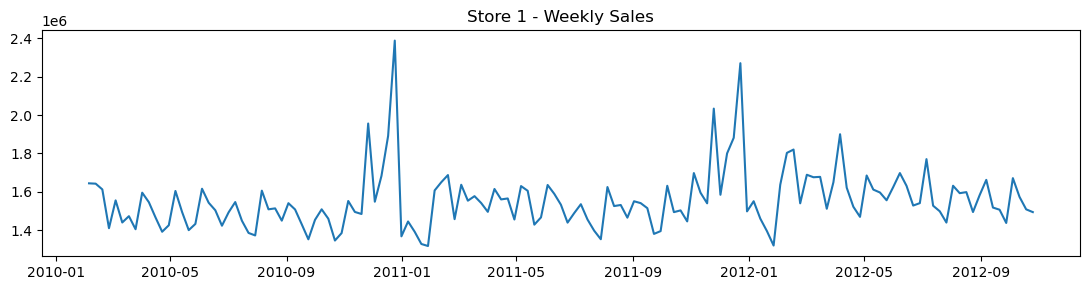

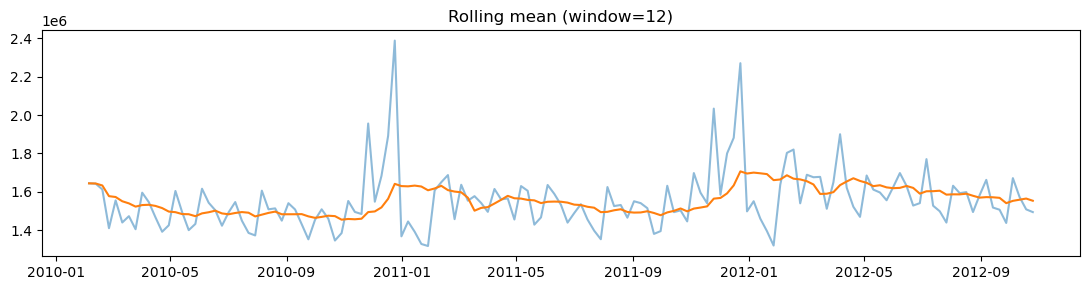

Total: 143, Train: 100, Val: 21, Test: 22


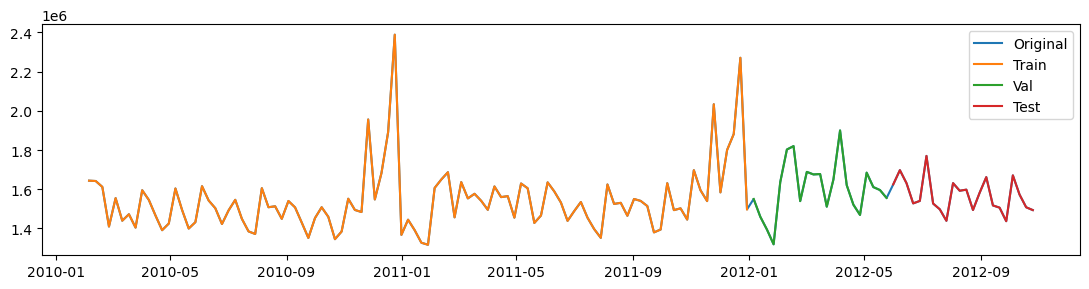

In [5]:
# Cell 2 - pick an example store and split to train/val/test (time-based)
example_store = int(df['Store'].unique()[0])   # choose first store as example
print("Example store:", example_store)

store_df = df[df['Store'] == example_store].copy().set_index('Date').sort_index()
series = store_df['Weekly_Sales'].sort_index().dropna()

print("Data points:", len(series))
display(series.head())

# Plot raw series + rolling mean (quick trend check)
plt.figure(figsize=(11,3))
plt.plot(series, label='Weekly_Sales')
plt.title(f"Store {example_store} - Weekly Sales")
plt.tight_layout(); plt.show()

rolling = series.rolling(window=12, min_periods=1).mean()
plt.figure(figsize=(11,3))
plt.plot(series, alpha=0.5)
plt.plot(rolling)
plt.title("Rolling mean (window=12)")
plt.tight_layout(); plt.show()

# Time-based split
n = len(series)
n_train = int(0.7 * n)
n_val   = int(0.15 * n)
n_test  = n - n_train - n_val

train = series.iloc[:n_train]
val   = series.iloc[n_train:n_train + n_val]
test  = series.iloc[n_train + n_val:]

print(f"Total: {n}, Train: {len(train)}, Val: {len(val)}, Test: {len(test)}")
plt.figure(figsize=(11,3))
plt.plot(series, label='Original')
plt.plot(train, label='Train')
plt.plot(val, label='Val')
plt.plot(test, label='Test')
plt.legend()
plt.tight_layout(); plt.show()


We notice seasonality as there are spikes around Christmas and new year eve in every 52 weeks. so there is yearly seasonality, though there is no strong upward or downward trend. 

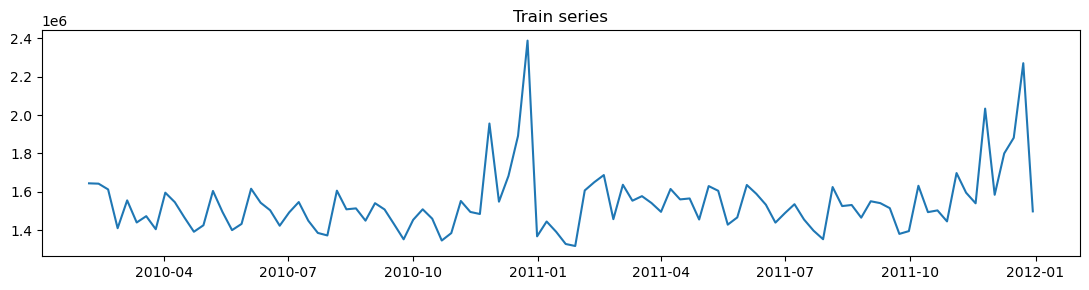

<Figure size 1100x300 with 0 Axes>

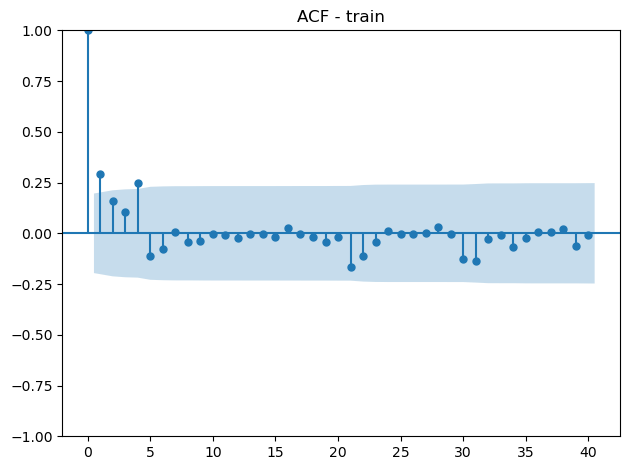

<Figure size 1100x300 with 0 Axes>

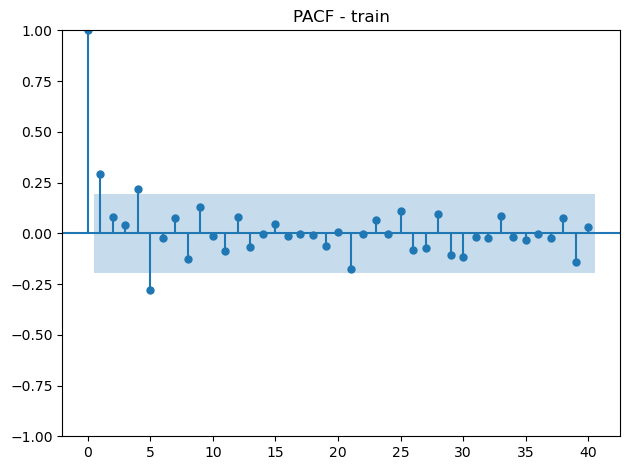

---- ADF test: train ----
ADF Stat: -3.4273  p-value: 0.0101  lags: 4  obs:95
  Crit 1%: -3.5011
  Crit 5%: -2.8925
  Crit 10%: -2.5833
Stationary? Yes (p<=0.05)
-------------------------------



In [6]:
# Cell 3 - Stationarity checks on train
def adf_test_print(s, label="Series"):
    print("---- ADF test:", label, "----")
    if len(s.dropna()) < 3:
        print("Series too short for ADF test.")
        return
    res = adfuller(s.dropna(), autolag='AIC')
    print("ADF Stat: %.4f  p-value: %.4f  lags: %d  obs:%d" % (res[0], res[1], res[2], res[3]))
    for k,v in res[4].items():
        print("  Crit %s: %.4f" % (k,v))
    print("Stationary?" , "Yes (p<=0.05)" if res[1] <= 0.05 else "No (p>0.05)")
    print("-------------------------------\n")

# Plot series, ACF, PACF and run ADF
lags_to_use = min(40, max(10, len(train)//2))
plt.figure(figsize=(11,3)); plt.plot(train); plt.title("Train series"); plt.tight_layout(); plt.show()
plt.figure(figsize=(11,3)); plot_acf(train.dropna(), lags=lags_to_use, title='ACF - train'); plt.tight_layout(); plt.show()
plt.figure(figsize=(11,3)); plot_pacf(train.dropna(), lags=lags_to_use, title='PACF - train'); plt.tight_layout(); plt.show()
adf_test_print(train, label='train')


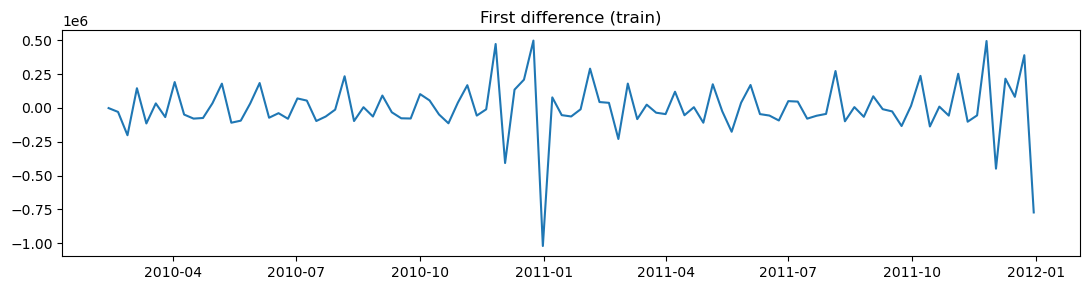

<Figure size 1100x300 with 0 Axes>

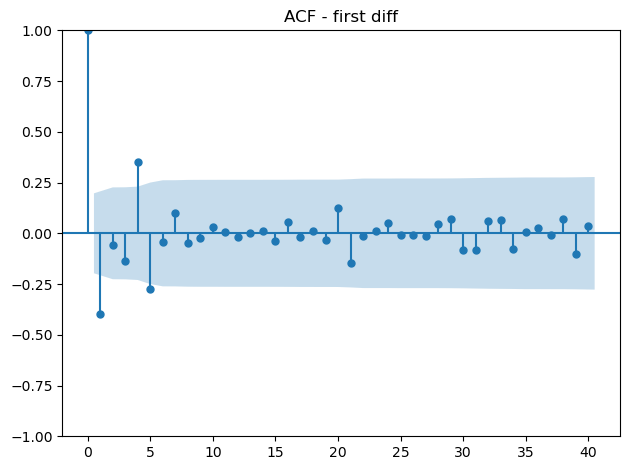

<Figure size 1100x300 with 0 Axes>

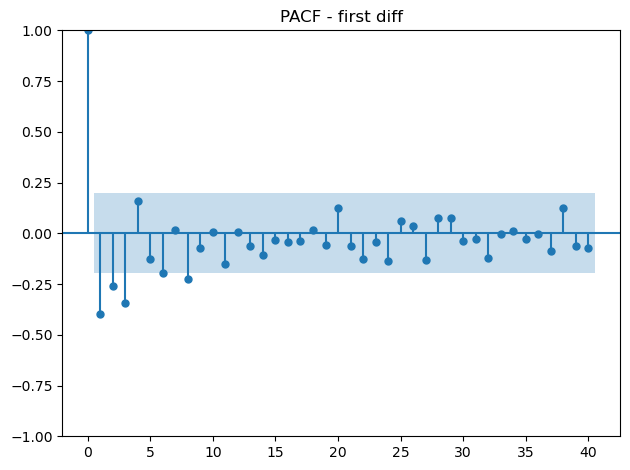

---- ADF test: first-diff(train) ----
ADF Stat: -5.3935  p-value: 0.0000  lags: 7  obs:91
  Crit 1%: -3.5043
  Crit 5%: -2.8939
  Crit 10%: -2.5840
Stationary? Yes (p<=0.05)
-------------------------------



In [7]:
# Cell 4 - differencing and check again
diff1 = train.diff().dropna()
plt.figure(figsize=(11,3)); plt.plot(diff1); plt.title("First difference (train)"); plt.tight_layout(); plt.show()

lags_to_use = min(40, max(10, len(diff1)//2))
plt.figure(figsize=(11,3)); plot_acf(diff1, lags=lags_to_use, title='ACF - first diff'); plt.tight_layout(); plt.show()
plt.figure(figsize=(11,3)); plot_pacf(diff1, lags=lags_to_use, title='PACF - first diff'); plt.tight_layout(); plt.show()
adf_test_print(diff1, label='first-diff(train)')

# If you suspect yearly seasonality (weekly data -> period=52), check seasonal diff
if len(train) > 52*2:
    sdiff = train.diff(52).dropna()
    plt.figure(figsize=(11,3)); plt.plot(sdiff); plt.title("Seasonal diff (lag=52)"); plt.tight_layout(); plt.show()
    plt.figure(figsize=(11,3)); plot_acf(sdiff, lags=lags_to_use, title='ACF - seasonal diff'); plt.tight_layout(); plt.show()
    plt.figure(figsize=(11,3)); plot_pacf(sdiff, lags=lags_to_use, title='PACF - seasonal diff'); plt.tight_layout(); plt.show()
    adf_test_print(sdiff, label='seasonal-diff(train,52)')


In [20]:
# Cell 5 - guidance
print("Manual p/q guidance:")
print("- If PACF cuts off after lag k and ACF tails -> AR(p=k).")
print("- If ACF cuts off after lag k and PACF tails -> MA(q=k).")
print("- If both tail slowly -> increase d (difference).")
print("Use the ACF/PACF of the differenced series above to pick p and q.")
# Default example start:
p,d,q = 1,0,1
print("Demo starting point: ARIMA(%d,%d,%d)" % (p,d,q))


Manual p/q guidance:
- If PACF cuts off after lag k and ACF tails -> AR(p=k).
- If ACF cuts off after lag k and PACF tails -> MA(q=k).
- If both tail slowly -> increase d (difference).
Use the ACF/PACF of the differenced series above to pick p and q.
Demo starting point: ARIMA(1,0,1)


In [21]:
# Cell 6 - fit ARIMA
model = ARIMA(train, order=(p,d,q))
fitted = model.fit()
print(fitted.summary())


                               SARIMAX Results                                
Dep. Variable:           Weekly_Sales   No. Observations:                  100
Model:                 ARIMA(1, 0, 1)   Log Likelihood               -1340.282
Date:                Sun, 05 Oct 2025   AIC                           2688.565
Time:                        00:59:01   BIC                           2698.986
Sample:                    02-05-2010   HQIC                          2692.782
                         - 12-30-2011                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.542e+06   3.67e+04     41.980      0.000    1.47e+06    1.61e+06
ar.L1          0.6900      0.270      2.552      0.011       0.160       1.220
ma.L1         -0.4476      0.327     -1.369      0.1

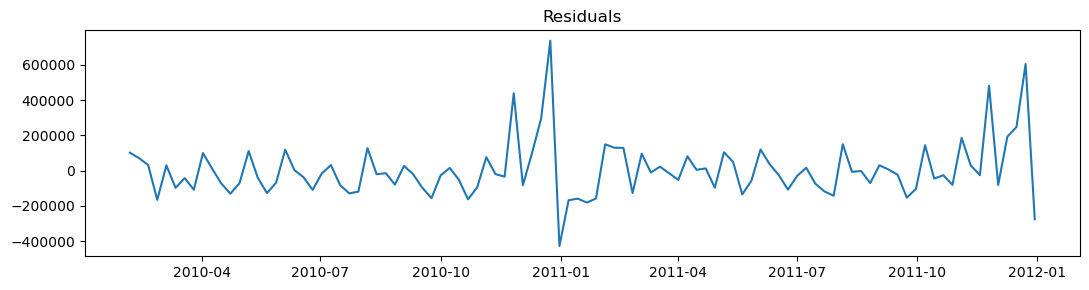

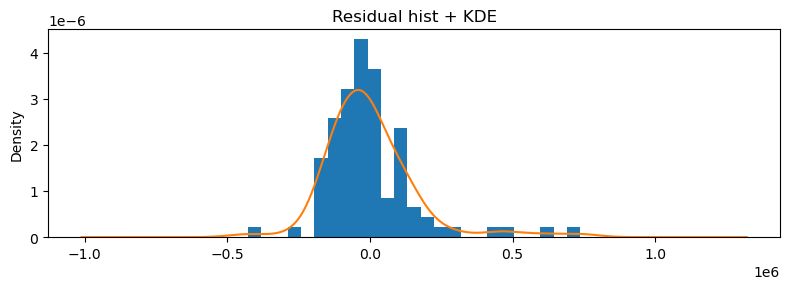

<Figure size 1100x300 with 0 Axes>

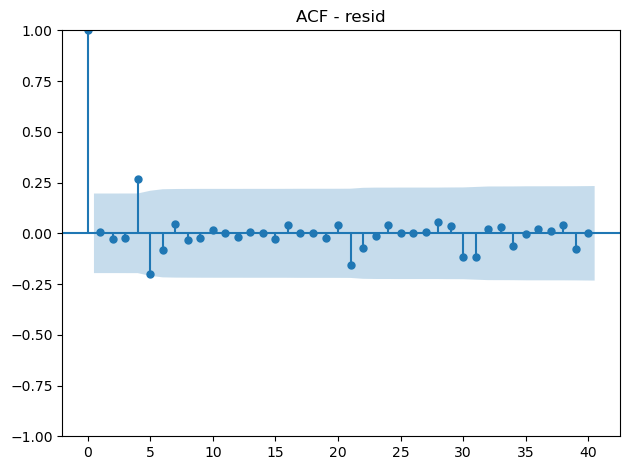

<Figure size 1100x300 with 0 Axes>

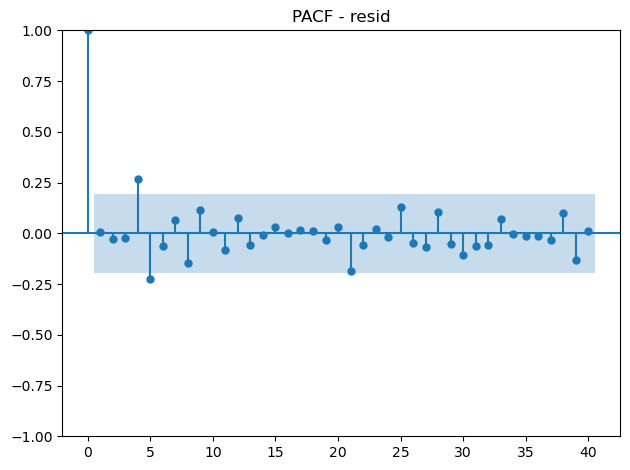

In [22]:
# Cell 7 - residuals diagnostics
resid = fitted.resid.dropna()
plt.figure(figsize=(11,3)); plt.plot(resid); plt.title("Residuals"); plt.tight_layout(); plt.show()
plt.figure(figsize=(8,3)); resid.plot(kind='hist', bins=25, density=True); resid.plot(kind='kde'); plt.title("Residual hist + KDE"); plt.tight_layout(); plt.show()
plt.figure(figsize=(11,3)); plot_acf(resid, lags=min(40, len(resid)-1), title='ACF - resid'); plt.tight_layout(); plt.show()
plt.figure(figsize=(11,3)); plot_pacf(resid, lags=min(40, len(resid)-1), title='PACF - resid'); plt.tight_layout(); plt.show()


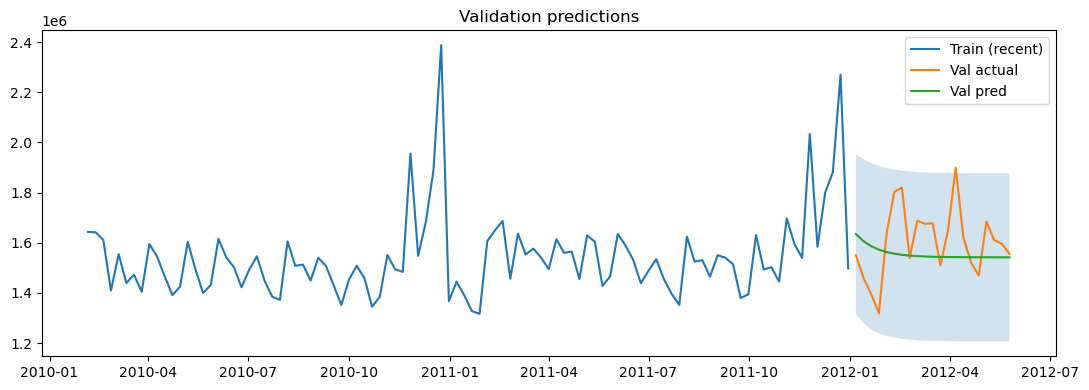

Validation MAE, MAPE, RMSE: 124988.05185115396 7.6932962089701435 154583.22683506296


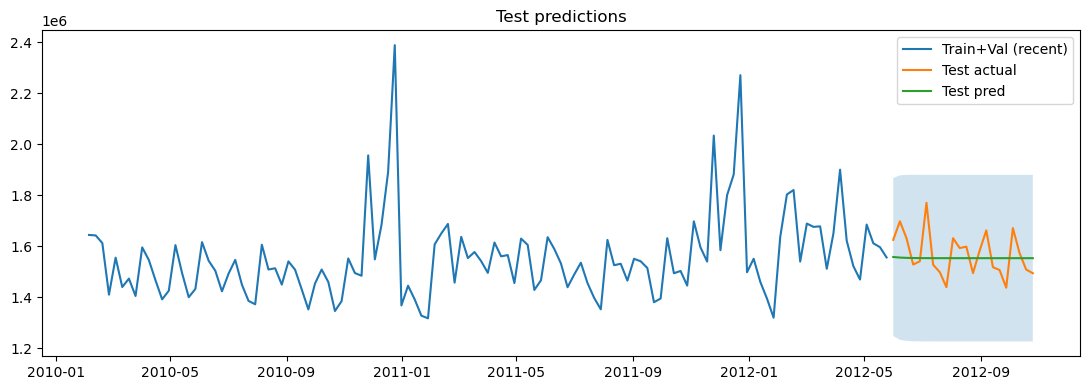

Test MAE, MAPE, RMSE: 69782.08112104451 4.382294827249806 84645.99733674215


In [23]:
# Cell 8 - forecast & evaluate
def mae(y, yhat): return np.mean(np.abs(y - yhat))
def mape(y, yhat): return np.mean(np.abs((y - yhat) / np.where(y==0, np.nan, y))) * 100
def rmse(y, yhat): return np.sqrt(np.mean((y - yhat)**2))

# Predict on validation using fitted (forecast steps = len(val))
if len(val) > 0:
    fc_val = fitted.get_forecast(steps=len(val))
    val_pred = pd.Series(fc_val.predicted_mean, index=val.index)
    val_conf = fc_val.conf_int()
    val_conf.index = val.index
    # plot
    plt.figure(figsize=(11,4))
    plt.plot(train[-len(train):], label='Train (recent)')
    plt.plot(val, label='Val actual')
    plt.plot(val_pred, label='Val pred')
    plt.fill_between(val.index, val_conf.iloc[:,0].values, val_conf.iloc[:,1].values, alpha=0.2)
    plt.legend(); plt.title("Validation predictions"); plt.tight_layout(); plt.show()
    print("Validation MAE, MAPE, RMSE:", mae(val, val_pred), mape(val, val_pred), rmse(val, val_pred))

# Refit on train+val and forecast test
train_val = pd.concat([train, val]) if len(val) > 0 else train
model_tv = ARIMA(train_val, order=(p,d,q)).fit()
if len(test) > 0:
    fc_test = model_tv.get_forecast(steps=len(test))
    test_pred = pd.Series(fc_test.predicted_mean, index=test.index)
    test_conf = fc_test.conf_int()
    test_conf.index = test.index
    plt.figure(figsize=(11,4))
    plt.plot(train_val[-len(train_val):], label='Train+Val (recent)')
    plt.plot(test, label='Test actual')
    plt.plot(test_pred, label='Test pred')
    plt.fill_between(test.index, test_conf.iloc[:,0].values, test_conf.iloc[:,1].values, alpha=0.2)
    plt.legend(); plt.title("Test predictions"); plt.tight_layout(); plt.show()
    print("Test MAE, MAPE, RMSE:", mae(test, test_pred), mape(test, test_pred), rmse(test, test_pred))


SARIMAX Validation MAE: 280277.61
SARIMAX Validation RMSE: 312145.14


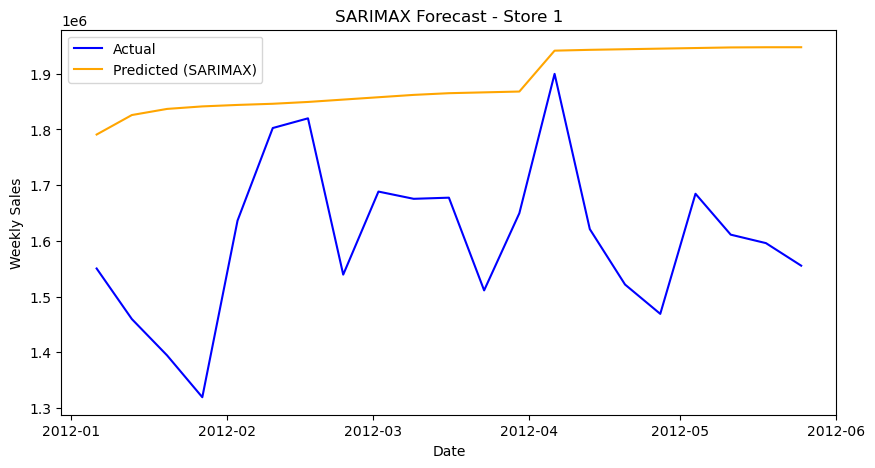

In [29]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Example: Using Store 1 for demonstration
store_id = 1
store_data = df[df['Store'] == store_id].copy()
store_data['Date'] = pd.to_datetime(store_data['Date'])
store_data = store_data.sort_values('Date')

# Define train/val/test split (70-15-15)
n = len(store_data)
train_end = int(0.7 * n)
val_end = int(0.85 * n)

train = store_data.iloc[:train_end]
val = store_data.iloc[train_end:val_end]
test = store_data.iloc[val_end:]

# Prepare exogenous variables
exog_cols = top_features
train_exog = train[exog_cols]
val_exog = val[exog_cols]
test_exog = test[exog_cols]

# Fit SARIMAX (same (p,d,q) as ARIMA)
sarimax_model = SARIMAX(train['Weekly_Sales'], exog=train_exog, order=(1,1,1))
sarimax_result = sarimax_model.fit(disp=False)

# Forecast using validation set
forecast = sarimax_result.predict(start=val.index[0], end=val.index[-1], exog=val_exog)

# Evaluate
mae = mean_absolute_error(val['Weekly_Sales'], forecast)
rmse = mean_squared_error(val['Weekly_Sales'], forecast, squared=False)

print(f"SARIMAX Validation MAE: {mae:.2f}")
print(f"SARIMAX Validation RMSE: {rmse:.2f}")

# Plot predicted vs actual
plt.figure(figsize=(10,5))
plt.plot(val['Date'], val['Weekly_Sales'], label='Actual', color='blue')
plt.plot(val['Date'], forecast, label='Predicted (SARIMAX)', color='orange')
plt.title(f"SARIMAX Forecast - Store {store_id}")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.legend()
plt.show()


In [24]:
# Cell 9 - optional auto_arima using pmdarima
try:
    import pmdarima as pm
    auto = pm.auto_arima(train, seasonal=False, stepwise=True, suppress_warnings=True,
                         error_action='ignore', max_p=5, max_q=5, max_d=2)
    print("Auto ARIMA order:", auto.order)
    print(auto.summary())
except Exception as e:
    print("pmdarima not installed. Install with: pip install pmdarima")


Auto ARIMA order: (1, 0, 0)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  100
Model:               SARIMAX(1, 0, 0)   Log Likelihood               -1340.960
Date:                Sun, 05 Oct 2025   AIC                           2687.920
Time:                        01:02:22   BIC                           2695.736
Sample:                    02-05-2010   HQIC                          2691.083
                         - 12-30-2011                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept   1.091e+06   1.03e+05     10.559      0.000    8.88e+05    1.29e+06
ar.L1          0.2927      0.059      4.983      0.000       0.178       0.408
sigma2      2.614e+10   

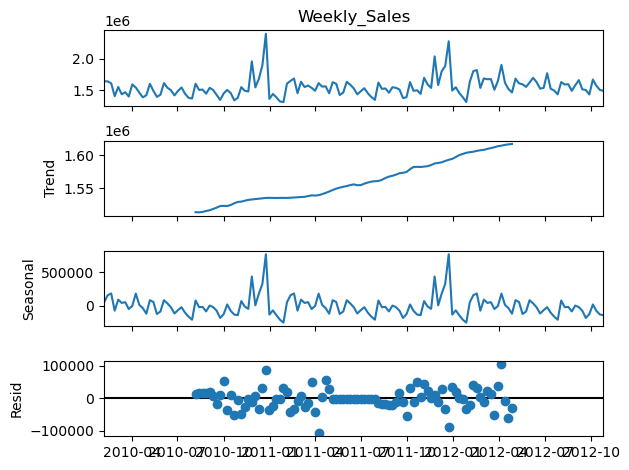

In [25]:
from statsmodels.tsa.seasonal import seasonal_decompose

result = seasonal_decompose(series, model='additive', period=52)  # 52 weeks in a year
result.plot()
plt.show()
